# WEEK 3 — LAB 1B: Convolution, Correlation and Difference Equations


**Name:** BARAKA MARTIN MDEKA
**Registration Number:** 240242436939
**Date:** 25/11/2026


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

ModuleNotFoundError: No module named 'numpy'

## Pre-lab

**(a)** Convolve $x(n) = \{1, -1, 2\}$ with $h(n) = \{2, 1, 0, 1\}$ by hand. The output has $3 + 4 - 1 = 6$ samples, $y(n) = \sum_k x(k)h(n-k)$:

| $n$ | terms | $y(n)$ |
|---|---|---|
| 0 | $x(0)h(0) = 1\cdot2$ | 2 |
| 1 | $x(0)h(1) + x(1)h(0) = 1 - 2$ | −1 |
| 2 | $x(0)h(2) + x(1)h(1) + x(2)h(0) = 0 - 1 + 4$ | 3 |
| 3 | $x(0)h(3) + x(1)h(2) + x(2)h(1) = 1 + 0 + 2$ | 3 |
| 4 | $x(1)h(3) + x(2)h(2) = -1 + 0$ | −1 |
| 5 | $x(2)h(3) = 2$ | 2 |

$$y(n) = \{2,\,-1,\,3,\,3,\,-1,\,2\}$$

**(b)** Is $y(n) = n\,x(n)$ time-invariant? **Test:** delay the input by $n_0$, i.e. feed $x_1(n) = x(n-n_0)$. The output is

$$y_1(n) = n\,x(n-n_0).$$

Delaying the original output by $n_0$ gives

$$y(n-n_0) = (n-n_0)\,x(n-n_0).$$

Since $y_1(n) \neq y(n-n_0)$ in general (they differ by the factor $n$ versus $n-n_0$), the system is **not time-invariant** (it is linear, but time-varying).

## Task 3.1 — Convolution from the definition

In [12]:
def conv(x, h):
    x = np.asarray(x, dtype=float); h = np.asarray(h, dtype=float)
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print("conv        :", conv([1, 2, 3, 1], [1, 1, 1]), "  (expect [1 3 6 6 4 1])")
print("np.convolve :", np.convolve([1, 2, 3, 1], [1, 1, 1]))

# Pre-lab (a) check
print("\nPre-lab (a):")
print("conv        :", conv([1, -1, 2], [2, 1, 0, 1]))
print("np.convolve :", np.convolve([1, -1, 2], [2, 1, 0, 1]))

conv        : [1. 3. 6. 6. 4. 1.]   (expect [1 3 6 6 4 1])
np.convolve : [1 3 6 6 4 1]

Pre-lab (a):
conv        : [ 2. -1.  3.  3. -1.  2.]
np.convolve : [ 2 -1  3  3 -1  2]


In [13]:
# Timing comparison, two random sequences of length 2000
rng = np.random.default_rng(0)
a, b = rng.standard_normal(2000), rng.standard_normal(2000)

t0 = time.perf_counter(); y_loop = conv(a, b);        t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_np   = np.convolve(a, b); t_np   = time.perf_counter() - t0

print(f"double loop conv : {t_loop:.4f} s")
print(f"np.convolve      : {t_np:.6f} s")
print(f"speed-up         : about {t_loop/t_np:,.0f} x")
print("results agree    :", np.allclose(y_loop, y_np))

double loop conv : 2.1078 s
np.convolve      : 0.000953 s
speed-up         : about 2,212 x
results agree    : True


**Observation.** Both functions give the same result (checked with `np.allclose`), including the pre-lab answer $\{2,-1,3,3,-1,2\}$. `np.convolve` is faster by several orders of magnitude (see the printed speed-up; the exact figure depends on your computer).

## Task 3.2 — Smoothing a noisy signal by convolution

  M   RMS error vs clean sine
  -                     0.509   (noisy input)
  3                     0.304   (peak amplitude 1.966)
  9                     0.187   (peak amplitude 1.387)
 25                     0.271   (peak amplitude 0.758)


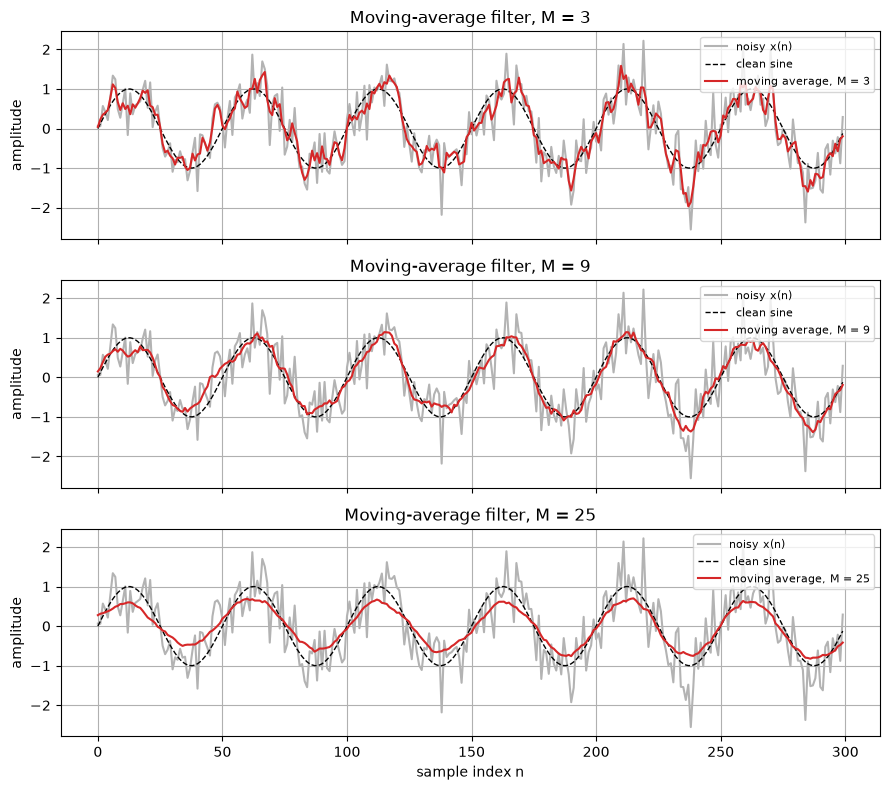

In [14]:
rng = np.random.default_rng(0)
n = np.arange(300)
clean = np.sin(2*np.pi*n/50)
x = clean + 0.5*rng.standard_normal(300)

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
print(f"{'M':>3} {'RMS error vs clean sine':>25}")
print(f"{'-':>3} {np.sqrt(np.mean((x-clean)**2)):25.3f}   (noisy input)")
for ax, M in zip(axes, [3, 9, 25]):
    h = np.ones(M)/M
    y = np.convolve(x, h, mode="same")
    ax.plot(n, x, color="0.7", label="noisy x(n)")
    ax.plot(n, clean, "k--", lw=1, label="clean sine")
    ax.plot(n, y, "C3", label=f"moving average, M = {M}")
    ax.set_ylabel("amplitude"); ax.set_title(f"Moving-average filter, M = {M}")
    ax.legend(loc="upper right", fontsize=8); ax.grid(True)
    inner = slice(M, -M)   # ignore edge effects of mode='same'
    print(f"{M:3d} {np.sqrt(np.mean((y[inner]-clean[inner])**2)):25.3f}   (peak amplitude {np.max(np.abs(y[inner])):.3f})")
axes[-1].set_xlabel("sample index n")
plt.tight_layout(); plt.show()

**Trade-off.** A longer moving average averages more noisy samples, so the noise falls roughly as $1/\sqrt{M}$: $M=3$ removes some noise but the output is still ragged, $M=9$ is much smoother, and $M=25$ is smoothest. But the filter also acts as a low-pass filter on the signal itself. The sine has a period of 50 samples; with $M=25$ (half a period) the peak amplitude is clearly reduced (printed above) and the waveform is distorted, while $M=3$ and $M=9$ keep it almost intact. The printed RMS errors show the compromise: the error falls from $M=3$ to $M=9$, then rises again at $M=25$, where the distortion of the sine outweighs the extra noise reduction. So more smoothing means less noise but more distortion (amplitude loss and blurring of fast changes); $M$ must be chosen to match the signal bandwidth. (RMS errors are measured away from the edges, where `mode="same"` zero-pads.)

## Task 3.3 — Testing linearity and time-invariance numerically

In [15]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]           # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]        # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


**Explanation (handout §1.7).** A system is linear if $T[ax_1 + bx_2] = aT[x_1] + bT[x_2]$ (superposition) and time-invariant if delaying the input delays the output by the same amount.

| system | linear | time-invariant | reason |
|---|---|---|---|
| $y = x^2$ | **No** | Yes | $(ax_1+bx_2)^2$ contains the cross term $2ab\,x_1x_2$, so superposition fails. It has no explicit dependence on $n$, so a delay passes straight through. |
| $y = n\,x(n)$ | Yes | **No** | Scaling and adding commute with multiplying by $n$. But the gain $n$ depends on time, so delaying the input gives $n\,x(n-n_0) \neq (n-n_0)\,x(n-n_0)$. |
| moving average | Yes | Yes | Weighted sum of delayed inputs with fixed coefficients: an LTI system (FIR convolution with $h = \{1/3,1/3,1/3\}$). |

## Task 3.4 — Finding a hidden delay with cross-correlation

estimated delay: 37 samples


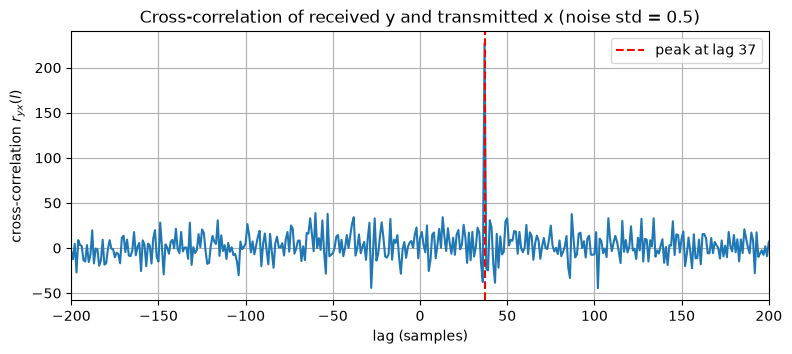

In [16]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)                  # transmitted signal
true_delay = 37
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
est = lags[np.argmax(r)]
print("estimated delay:", est, "samples")

plt.plot(lags, r)
plt.xlim(-200, 200)
plt.axvline(est, color="r", ls="--", label=f"peak at lag {est}")
plt.xlabel("lag (samples)"); plt.ylabel("cross-correlation $r_{yx}(l)$")
plt.title("Cross-correlation of received y and transmitted x (noise std = 0.5)")
plt.legend(); plt.grid(True); plt.show()

noise std = 0.5: estimated delay =  37 samples (correct)
noise std =   1: estimated delay =  37 samples (correct)
noise std =   2: estimated delay =  37 samples (correct)
noise std =   4: estimated delay =  87 samples (WRONG)


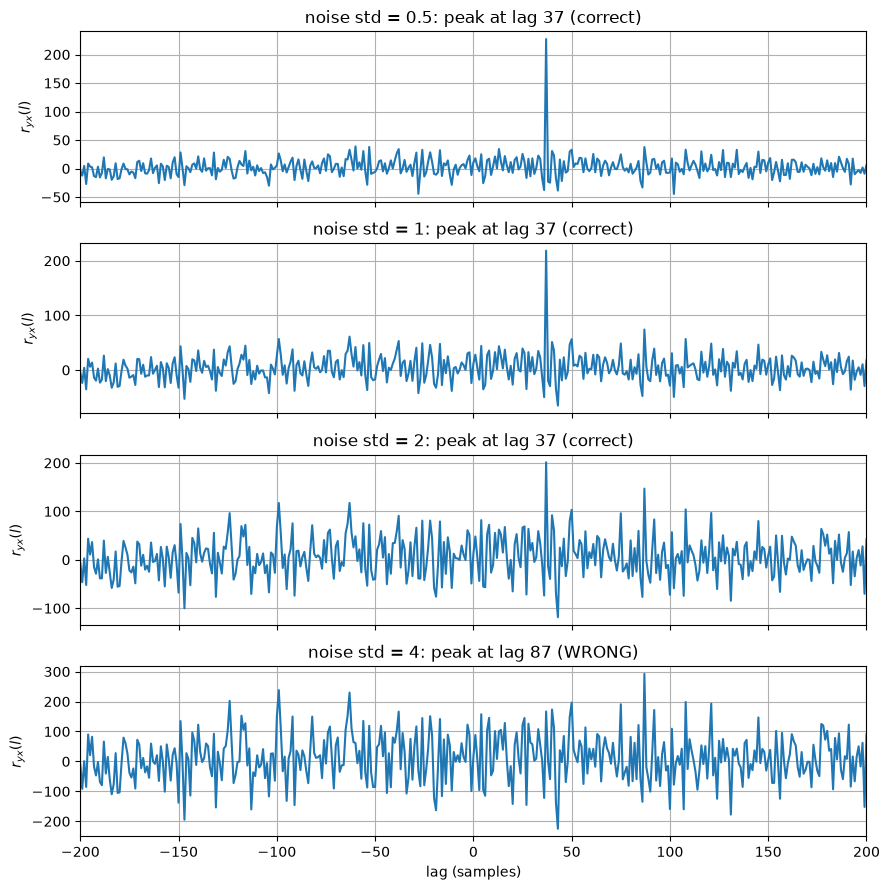

In [17]:
# Increase the noise standard deviation: 1, 2 and 4 (same seed/procedure as above)
sigmas = [0.5, 1, 2, 4]
fig, axes = plt.subplots(len(sigmas), 1, figsize=(9, 9), sharex=True)
for ax, s in zip(axes, sigmas):
    rng = np.random.default_rng(1)
    x = rng.standard_normal(500)
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + s*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    est = lags[np.argmax(r)]
    ok = "correct" if est == true_delay else "WRONG"
    print(f"noise std = {s:>3}: estimated delay = {est:3d} samples ({ok})")
    ax.plot(lags, r); ax.set_xlim(-200, 200); ax.grid(True)
    ax.set_ylabel("$r_{yx}(l)$"); ax.set_title(f"noise std = {s}: peak at lag {est} ({ok})")
axes[-1].set_xlabel("lag (samples)")
plt.tight_layout(); plt.show()

In [18]:
# One seed is a single experiment, so repeat with 200 random seeds to see where it really starts to fail
def success_rate(s, trials=200):
    ok = 0
    for seed in range(trials):
        rng = np.random.default_rng(1000 + seed)
        x = rng.standard_normal(500)
        y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + s*rng.standard_normal(500)
        r = signal.correlate(y, x, mode="full")
        l = signal.correlation_lags(len(y), len(x), mode="full")
        ok += (l[np.argmax(r)] == true_delay)
    return ok/trials

print(f"{'noise std':>10} {'success rate (200 trials)':>26}")
for s in [0.5, 1, 2, 3, 4, 6, 8]:
    print(f"{s:10g} {100*success_rate(s):25.1f} %")

# Distance from the delay
c = 343.0
d = true_delay/fs
print(f"\ndelay = {true_delay} samples / {fs} Hz = {d*1e3:.0f} ms")
print(f"distance = c * delay = {c*d:.2f} m (one-way)")

 noise std  success rate (200 trials)
       0.5                     100.0 %
         1                     100.0 %
         2                     100.0 %
         3                      92.0 %
         4                      65.0 %
         6                      31.5 %
         8                      16.0 %

delay = 37 samples / 1000 Hz = 37 ms
distance = c * delay = 12.69 m (one-way)


**Observation.** The delay is recovered exactly (37 samples) for noise standard deviations 0.5, 1 and 2, and with the given seed the estimate **fails at 4** (the peak lands at a wrong lag). The 200-trial table shows the failure is gradual: the correlation peak has height about $0.6 \times 463 \approx 280$ (the 463 samples where the delayed copy overlaps $x$), while the noise floor of $r_{yx}$ grows in proportion to the noise standard deviation, so the peak eventually gets buried and an unrelated noise peak wins.

**Distance.** The delay is $37/1000 = 0.037$ s, so the distance is $343 \times 0.037 \approx 12.7$ m (one-way travel of the pulse).

## Task 3.5 — Difference equation

$y(n) - \tfrac34 y(n-1) + \tfrac18 y(n-2) = x(n) + x(n-1)$, so $b = \{1, 1\}$ and $a = \{1, -0.75, 0.125\}$.

 n    recursion      lfilter  closed form
 0     1.000000     1.000000     1.000000
 1     1.750000     1.750000     1.750000
 2     1.187500     1.187500     1.187500
 3     0.671875     0.671875     0.671875
 4     0.355469     0.355469     0.355469
 5     0.182617     0.182617     0.182617
 6     0.092529     0.092529     0.092529
 7     0.046570     0.046570     0.046570
 8     0.023361     0.023361     0.023361
 9     0.011700     0.011700     0.011700

all three agree: True


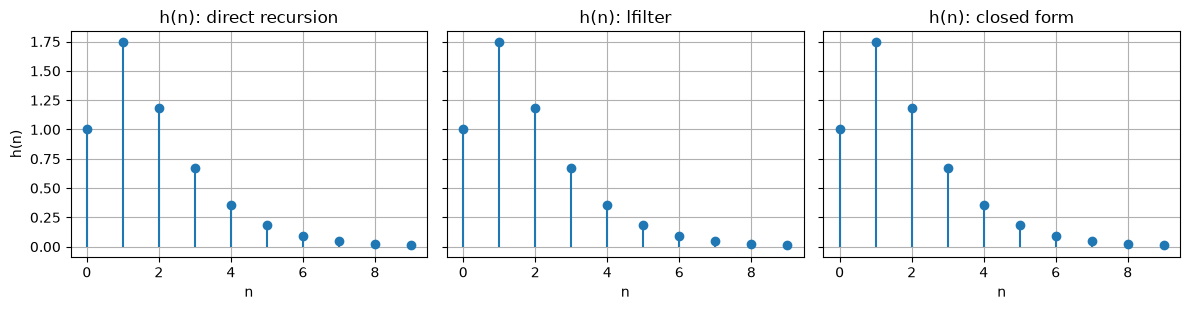

In [19]:
N = 10
imp = np.zeros(N); imp[0] = 1.0

# 1) direct recursion: h(n) = d(n) + d(n-1) + 0.75 h(n-1) - 0.125 h(n-2)
h_rec = np.zeros(N)
for n in range(N):
    h_rec[n] = imp[n] + (imp[n-1] if n >= 1 else 0) \
               + 0.75*(h_rec[n-1] if n >= 1 else 0) \
               - 0.125*(h_rec[n-2] if n >= 2 else 0)

# 2) lfilter
b, a = [1, 1], [1, -0.75, 0.125]
h_lf = signal.lfilter(b, a, imp)

# 3) closed form  h(n) = 6(0.5)^n - 5(0.25)^n
nn = np.arange(N)
h_cf = 6*0.5**nn - 5*0.25**nn

print(f"{'n':>2} {'recursion':>12} {'lfilter':>12} {'closed form':>12}")
for i in range(N):
    print(f"{i:2d} {h_rec[i]:12.6f} {h_lf[i]:12.6f} {h_cf[i]:12.6f}")
print("\nall three agree:", np.allclose(h_rec, h_lf) and np.allclose(h_lf, h_cf))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, h, name in zip(axes, [h_rec, h_lf, h_cf], ["direct recursion", "lfilter", "closed form"]):
    ax.stem(nn, h, basefmt=" "); ax.set_title(f"h(n): {name}")
    ax.set_xlabel("n"); ax.grid(True)
axes[0].set_ylabel("h(n)")
plt.tight_layout(); plt.show()

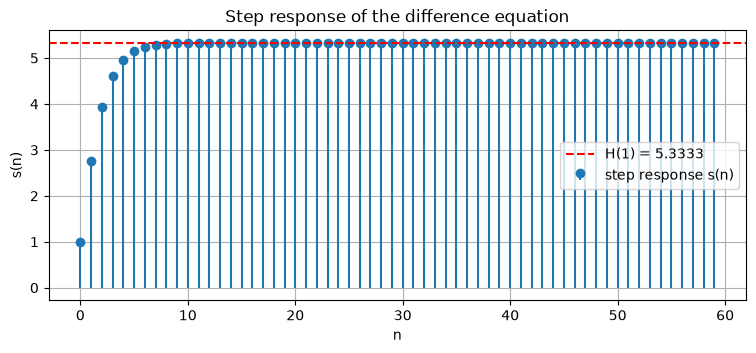

final value of s(n) (n = 59) = 5.333333
H(1) = sum(b)/sum(a) = 2/0.375 = 5.333333


In [20]:
# 4) step response and final value
Ns = 60
u = np.ones(Ns)
s = signal.lfilter(b, a, u)
H1 = np.sum(b)/np.sum(a)

plt.stem(np.arange(Ns), s, basefmt=" ", label="step response s(n)")
plt.axhline(H1, color="r", ls="--", label=f"H(1) = {H1:.4f}")
plt.xlabel("n"); plt.ylabel("s(n)"); plt.title("Step response of the difference equation")
plt.legend(); plt.grid(True); plt.show()

print(f"final value of s(n) (n = {Ns-1}) = {s[-1]:.6f}")
print(f"H(1) = sum(b)/sum(a) = {np.sum(b)}/{np.sum(a)} = {H1:.6f}")

**Observation.** The impulse responses from direct recursion, `lfilter` and the closed form $h(n) = 6(0.5)^n - 5(0.25)^n$ are identical (e.g. $h(0)=1$, $h(1)=1.75$), which is the content of Checkpoint 3. The step response settles at $H(1) = \sum b / \sum a = 2/0.375 = 5.3333$, matching the value reached by `lfilter`.

## Analysis questions

**1. Why is `np.convolve` so much faster than the double loop? How many multiplications for lengths $L$ and $M$?** Both need the same number of multiplications, $L \times M$ (so $LM$ multiply-adds; the output has $L+M-1$ samples). The double loop runs those $LM$ operations through the Python interpreter, which costs far more per operation than the arithmetic itself, while `np.convolve` runs the same loop in compiled C code on contiguous arrays. For long sequences, `scipy.signal.fftconvolve` is faster still, since it needs only about $N\log N$ operations.

**2. Which of the three systems in Task 3.3 are LTI? Could you have predicted this without code?** Only the moving average is LTI. $x^2$ is nonlinear, and $n\,x(n)$ is time-varying. Yes, this can be predicted by inspection: a squaring operation breaks superposition (cross term), an explicit factor $n$ in the equation means the system behaves differently at different times, and a fixed-coefficient weighted sum of delayed inputs is always LTI.

**3. Two engineering applications of cross-correlation in Tanzania.**
- *Locating leaks in water pipes:* sensors on either side of a suspected leak record the leak noise; the cross-correlation peak gives the arrival-time difference, and with the known wave speed it gives the leak position. This helps water utilities reduce non-revenue water.
- *Radar and GPS:* a radar at an airport correlates the received echo with the transmitted pulse to find the delay (range), and a GPS receiver correlates the received satellite signal with its own copy of the satellite's code to measure the delay and hence the distance.

**4. Is the system in Task 3.5 FIR or IIR? Stable?** It is **IIR**: $h(n) = 6(0.5)^n - 5(0.25)^n$ never becomes exactly zero (the feedback terms $a_1, a_2$ are non-zero), so the impulse response has infinite duration. It is **stable**: both terms decay geometrically, so $h(n)$ is absolutely summable:

$$\sum_{n=0}^{\infty}|h(n)| = \sum_{n=0}^{\infty}\left[6(0.5)^n - 5(0.25)^n\right] = \frac{6}{1-0.5} - \frac{5}{1-0.25} = 12 - 6.667 = 5.333 < \infty$$

(all $h(n) > 0$, so $|h| = h$). Equivalently, the poles are at $z = 0.5$ and $z = 0.25$, both inside the unit circle. The sum equals $H(1)$, consistent with the step-response final value.

## AI-use statement

**AI tools used:** DeepSeek
**Used for:** formatting the notebook, explaining an error in Task 3.4, and giving to me some line of code that was difficult to me. 
**How I verified the output:** compared `conv` with `np.convolve`; checked the three impulse responses against each other; ran Restart and Run All
